In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn import linear_model
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
df1=pd.read_csv('newbj_LianJia.csv', header=0,
                usecols=[1,2,3,4,5,6,7,8,9,10], encoding='gbk')
print(df1)

     floor lift district street community    area toward   model     rent  \
0      中楼层    无       房山     良乡     行宫园二里   85.00     南北  2室2厅1卫   3500.0   
1      低楼层    有       顺义   顺义其它      尚峯壹號  107.00      南  3室0厅1卫   5400.0   
2      中楼层    无       大兴    西红门       同兴园   72.00     南北  2室1厅1卫   3800.0   
3      中楼层    有       顺义    后沙峪     智地香蜜湾   71.13      东  3室0厅2卫   6900.0   
4      中楼层    有       朝阳    酒仙桥      丽都壹号   54.41      东  2室1厅1卫   9800.0   
...    ...  ...      ...    ...       ...     ...    ...     ...      ...   
4317   中楼层    有       通州   通州其它  首开万科城市之光   52.89      东  3室0厅1卫   4200.0   
4318   中楼层    有       朝阳     双桥     中建玲珑山   58.90      南  2室0厅1卫   5500.0   
4319   中楼层    有       朝阳  中央别墅区       瑞悦府   89.56      南  3室1厅1卫   8000.0   
4320   高楼层    有       朝阳     双井      百环家园  100.00     东南  2室1厅1卫   9000.0   
4321   低楼层    无       怀柔     怀柔    天恒半山世家  194.21   东南西北  5室2厅5卫  18000.0   

      totalfloor  
0              6  
1             17  
2              6  

In [4]:
def apart_room(x):
    '''
    分割字符串，提取“室”
    '''
    room=x.split('室')[0]
    return int(room)
def apart_hall(x):
    '''
    分割字符串,提取"厅"
    '''
    hall=x.split('厅')[0].split('室')[1]
    return int(hall)
def apart_wc(x):
    '''
    分割字符串,提取"卫"
    '''
    wc=x.split('卫')[0].split('厅')[1]
    return int(wc)


In [5]:
df1['bedroom']=df1['model'].map(apart_room)
df1['livingroom']=df1['model'].map(apart_hall)
df1['bathroom']=df1['model'].map(apart_wc)
df1.drop(columns=['model'],inplace=True)       #删除原数据集中的 model 列

# 对floot和lift属性进行自定义编码
map1= {'地下室':0, '低楼层':1, '中楼层':2, '高楼层':3}
df1['floor']= df1['floor'].map(map1)
map2= {'未知':3, '有':1, '无':2}
df1['lift']=df1['lift'].map(map2)

#对 district,street,community 和 toward 属性使用 LabelEncoder 进行编码
labelE=LabelEncoder()

labelE.fit(df1['district'])
df1['district']=labelE.transform(df1['district'])

labelE.fit(df1['street'])
df1['street']=labelE.transform(df1['street'])

labelE.fit(df1['community'])
df1['community']=labelE.transform(df1['community'])

labelE.fit(df1['toward'])
df1['toward']=labelE.transform(df1['toward'])

# 将重新编码后的数据保存为 rent.csv 文件
df1.to_csv('rent.csv', index=False)

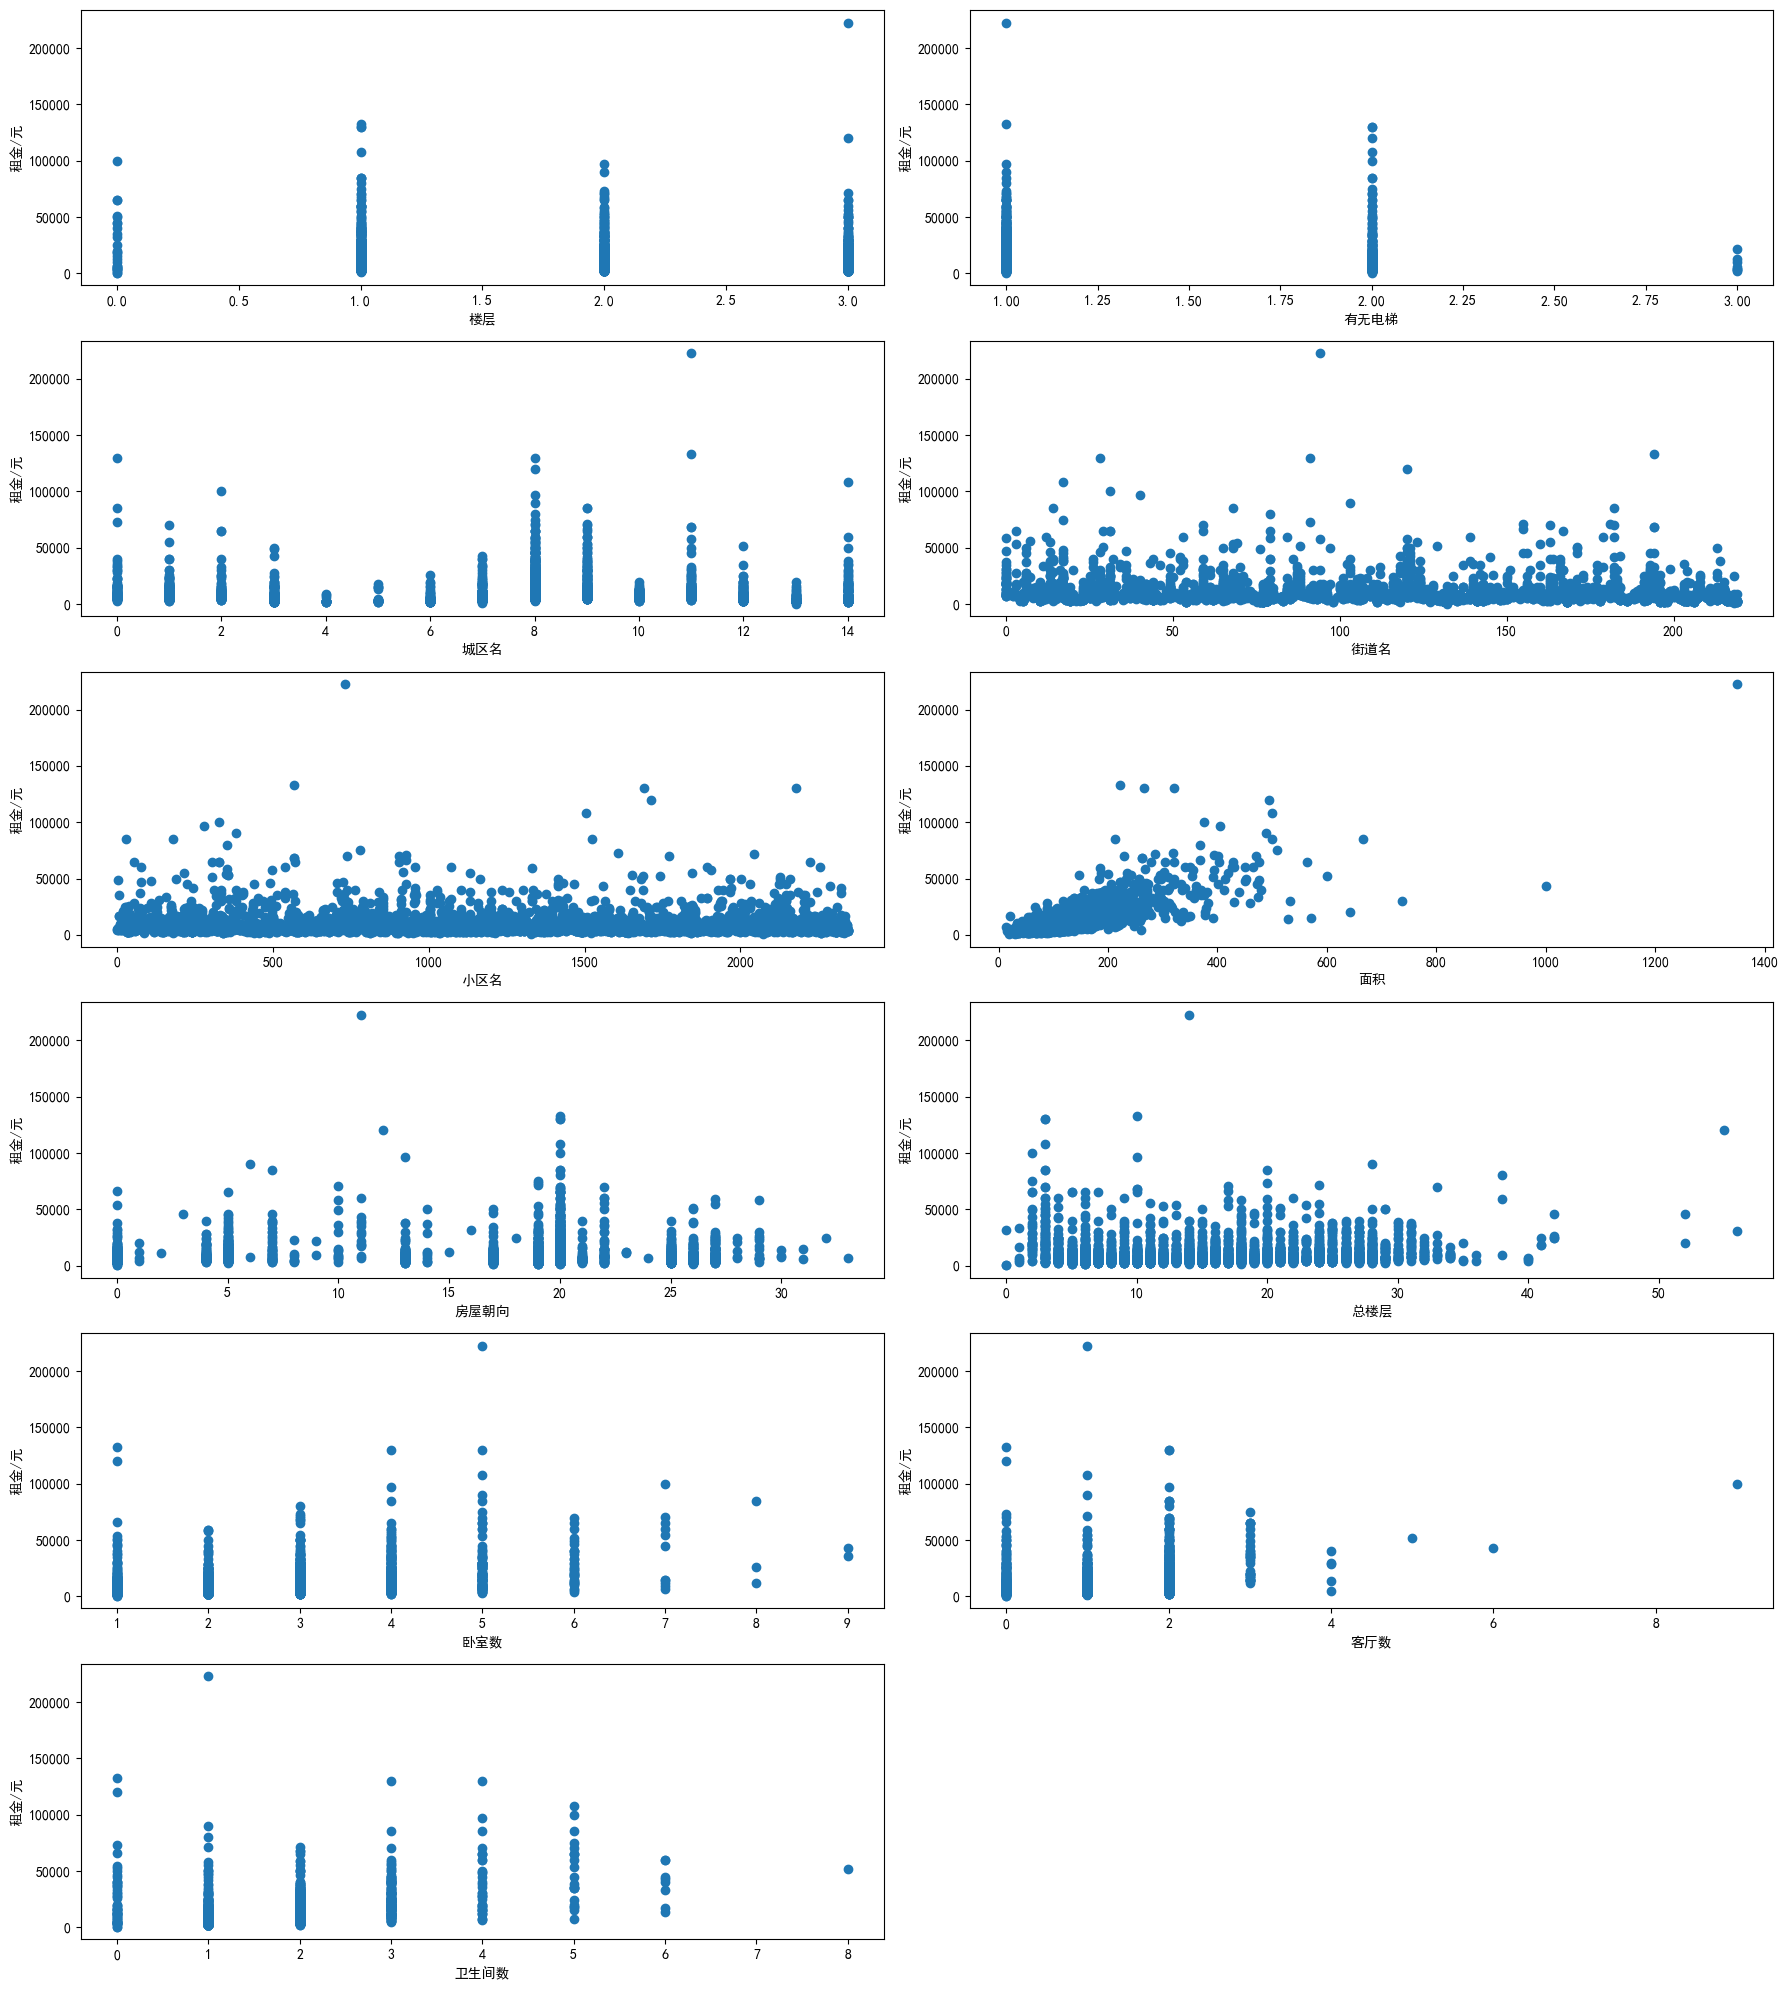

In [6]:
df2=df1.drop(columns=['rent'])
y=df1['rent'].values
colname=df2.columns
plt.rcParams['font.sans-serif']=['SimHei']           #调整字体设置
plt.figure(figsize=(18,20))
plt.subplots_adjust(wspace=0)
xlabel_dicts={"floor":"楼层","lift":"有无电梯","district":"城区名","street":"街道名",
              "community":"小区名","area":"面积","toward":"房屋朝向","totalfloor":"总楼层",
              "bedroom":"卧室数","livingroom":"客厅数","bathroom":"卫生间数"}
                                                              #设置图中特征属性名为中文

for i in range(11):
    plt.subplot(6,2,i+1)
    plt.scatter(df2[colname[i]],y)
    plt.xlabel(xlabel_dicts[colname[i]])
    plt.ylabel('租金/元')
plt.tight_layout()
plt.show()

In [7]:
corr = df1[['floor', 'lift', 'district', 'street', 'community', 'area', 'toward',
            'totalfloor','bedroom', 'livingroom', 'bathroom', 'rent']].corr()
print(corr)

               floor      lift  district    street  community      area  \
floor       1.000000  0.042062 -0.004999  0.038270  -0.002216 -0.135462   
lift        0.042062  1.000000  0.056651  0.081721  -0.004339 -0.085261   
district   -0.004999  0.056651  1.000000  0.087066   0.043552 -0.005809   
street      0.038270  0.081721  0.087066  1.000000   0.097504 -0.068962   
community  -0.002216 -0.004339  0.043552  0.097504   1.000000 -0.006717   
area       -0.135462 -0.085261 -0.005809 -0.068962  -0.006717  1.000000   
toward     -0.001167  0.099664  0.007428  0.019166   0.015352  0.035247   
totalfloor -0.040864 -0.638361 -0.046526 -0.084634  -0.056223  0.021097   
bedroom    -0.064588 -0.015538 -0.027661 -0.037879  -0.000816  0.645701   
livingroom -0.058526  0.136278  0.039233  0.013170   0.015353  0.502622   
bathroom   -0.115969 -0.052500 -0.008208 -0.065740  -0.012616  0.692222   
rent       -0.110143 -0.131319  0.004679 -0.132210  -0.040569  0.768255   

              toward  to

In [8]:
x=df1['area']
y=df1['rent']
x=np.array([x]).T
y=np.array([y]).T

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=1, test_size=0.20)

lr = linear_model.LinearRegression()
lr.fit(x_train, y_train)

# 截距 b
b = lr.intercept_

# 斜率 k
k = lr.coef_

print('线性方程的截距为：', b)
print('线性方程的斜率为：', k)

# 输出线性回归方程
print('rent=', '(', round(k[0,0], 2), ')', ' * ', 'area', '+', '(', round(b[0], 2), ')')

线性方程的截距为： [-2030.20533106]
线性方程的斜率为： [[117.93768023]]
rent= ( 117.94 )  *  area + ( -2030.21 )


In [ ]:
plt.rcParams['font.sans-serif'] = ['SimHei']    #调整字体设置
plt.plot(x_train, y_train, 'k.')
y1 = k * x_train + b
plt.plot(x_train, y1, 'r-')
plt.xlabel('面积')
plt.ylabel('租金/元')
plt.show()

In [ ]:
from sklearn.metrics import r2_score

y_pred_test = lr.predict(x_test)

print("测试集的决定系数={:.3f}".format(lr.score(x_test, y_test)))
print("测试集的决定系数={:.3f}".format(r2_score(y_test, y_pred_test)))

print("训练集的决定系数={:.3f}".format(lr.score(x_train, y_train)))